In [1]:
import os
import subprocess
try:
    _printenv = subprocess.run(
        ['bash', '-c', 'source ~/.bashrc 2>/dev/null && printenv'],
        text=True, capture_output=True, timeout=10,
    ).stdout
    for _line in _printenv.splitlines():
        if '=' in _line:
            _k, _v = _line.split('=', 1)
            os.environ.setdefault(_k, _v)
except Exception:
    pass
if 'PDK_ROOT' in os.environ and 'PDK' in os.environ:
    os.environ.setdefault('PDKPATH', os.path.join(os.environ['PDK_ROOT'], os.environ['PDK']))

import gdstk
import svgutils.transform as sg
import IPython.display
from IPython.display import clear_output
import ipywidgets as widgets

# Redirect all outputs here
hide = widgets.Output()

def display_gds(gds_file,path,scale = 3):
  
  # Generate an SVG image
  top_level_cell = gdstk.read_gds(gds_file).top_level()[0]
  top_level_cell.write_svg(os.path.join(path,'out.svg'))
    
  # Scale the image for displaying
  fig = sg.fromfile(os.path.join(path,'out.svg'))
  fig.set_size((str(float(fig.width) * scale), str(float(fig.height) * scale)))
  fig.save(os.path.join(path,'out.svg'))

  # Display the image
  IPython.display.display(IPython.display.SVG(os.path.join(path,'out.svg')))
  os.remove(os.path.join(path,'out.gds'))

def display_component(component,path,scale = 3):
  # Save to a GDS file
  with hide:
    component.write_gds(os.path.join(path,'out.gds'))
  display_gds(os.path.join(path,'out.gds'),path,scale)


# %%
import os
import gdsfactory as gf
from gdsfactory import Component
from glayout import MappedPDK, sky130
from glayout import nmos, pmos
from glayout import via_stack
from glayout import rename_ports_by_orientation
from glayout import tapring
from glayout.primitives.mimcap import mimcap_array
from glayout.routing.straight_route import straight_route
from glayout.routing.c_route import c_route
from glayout.routing.L_route import L_route
from glayout.util.comp_utils import evaluate_bbox, prec_center, prec_ref_center, align_comp_to_port
from glayout.util.port_utils import add_ports_perimeter,print_ports
from glayout.util.snap_to_grid import component_snap_to_grid
from glayout.spice.netlist import Netlist

pdk = sky130
# Base parameters for PMOS and NMOS
stdp_config = {
    "pdk": sky130,
    "layout_rules": {
        "spacing": pdk.util_max_metal_seperation()+2,
        "routing_metal": "met2",
        "dummy_devices": False,
        "tie_layers": ("met2", "met1"),
        "sd_rmult": 1,
    },
}

nmos_kwargs = {
    "with_tie": True,
    "with_dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": False,
    "with_substrate_tap":False
}

pmos_kwargs = {
    "with_tie": True,
    "dnwell": False,
    "sd_route_topmet": "met2",
    "gate_route_topmet": "met2",
    "sd_route_left": True,
    "rmult": None,
    "gate_rmult": 1,
    "interfinger_rmult": 1,
    "substrate_tap_layers": ("met2","met1"),
    "dummy_routes": False,
    "with_substrate_tap":False
}



In [2]:
current_mirror = Component(name="current_mirror")
current_mirror.name = "current_mirror"
rules = stdp_config["layout_rules"]
spacing = rules["spacing"]
tie_layers = rules["tie_layers"]
sd_rmult = rules["sd_rmult"]


#Placement
m1 = nmos(pdk, width=2, length=0.28, fingers=2, with_dummy=(False, False),  tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)
m2 = nmos(pdk, width=2, length=4, fingers=2, with_dummy=(False, False),  tie_layers=tie_layers, sd_rmult=sd_rmult, **nmos_kwargs)
m3 = pmos(pdk, width=2, length=0.5, fingers=4, with_dummy=(False, False),  tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)
m4 = pmos(pdk, width=1.6, length=0.5, with_dummy=(False, False), tie_layers=tie_layers, sd_rmult=sd_rmult, **pmos_kwargs)

m1.name = "M1" 
m2.name = "M2" 
m3.name = "M3" 
m4.name = "M4" 

m1_ref = current_mirror << m1
m2_ref = current_mirror << m2
m3_ref = current_mirror << m3
m4_ref = current_mirror << m4


bottom_row_y = evaluate_bbox(m1)[1]/2 
top_row_y = bottom_row_y + evaluate_bbox(m3)[1] + 1

m1_ref.move((evaluate_bbox(m1)[0]/2,bottom_row_y))
m2_ref.move((m1_ref.xmax + evaluate_bbox(m2_ref)[0]/2 + spacing , bottom_row_y))


m4_ref.move((evaluate_bbox(m1)[0]/2 ,top_row_y ))
m3_ref.move((m4_ref.xmax + evaluate_bbox(m3)[0]/2 + spacing,top_row_y))



2026-10-21 23:59:43.466 | INFO     | gdsfactory.pdk:activate:337 - 'sky130' PDK is now active


ComponentReference (parent Component "M3", ports ['multiplier_0_gate_W', 'gate_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_layer_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_via_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_bottom_met_W', 'multiplier_0_row0_col0_rightsd_array_row0_col0_top_met_W', 'multiplier_0_row0_col1_rightsd_array_row0_col0_bottom_layer_W', 'multiplier_0_row0_col1_rightsd_array_row0_col0_bottom_via_W', 'multiplier_0_row0_col1_rightsd_array_row0_col0_bottom_met_W', 'multiplier_0_row0_col1_rightsd_array_row0_col0_top_met_W', 'multiplier_0_row0_col2_rightsd_array_row0_col0_bottom_layer_W', 'multiplier_0_row0_col2_rightsd_array_row0_col0_bottom_via_W', 'multiplier_0_row0_col2_rightsd_array_row0_col0_bottom_met_W', 'multiplier_0_row0_col2_rightsd_array_row0_col0_top_met_W', 'multiplier_0_row0_col3_rightsd_array_row0_col0_bottom_layer_W', 'multiplier_0_row0_col3_rightsd_array_row0_col0_bottom_via_W', 'multiplier_0_row0_col3_rightsd_arra

2026-10-21 23:59:49.120 | WARNING  | gdsfactory.klive:show:48 - Could not connect to klive server. Is klayout open and klive plugin installed?


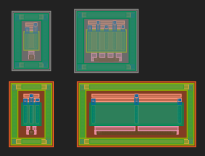

In [3]:
current_mirror.show()
display_component(current_mirror, scale = 1,path=".")

In [4]:
# =========================================================================
# 4. ADD AVDD & AVSS POWER RAILS AND CONNECT SUPPLY NODES
# =========================================================================

bbox = evaluate_bbox(current_mirror)
top_y = current_mirror.ymax + 1.0
bottom_y = current_mirror.ymin - 2.0

# Draw horizontal metal2 power rails
avdd_rail = current_mirror << gf.components.rectangle(
    size=(bbox[0]+4, 1.0), 
    layer=pdk.get_layer("met4")
)
avdd_rail.move((-2, top_y))

avss_rail = current_mirror << gf.components.rectangle(
    size=(bbox[0]+4, 1.0), 
    layer=pdk.get_layer("met4")
)
avss_rail.move((-2, bottom_y))

# Crear vias internas (nodos de conexión)
viam2m4 = via_stack(pdk, "met2", "met5", centered=True)

# Vía en VDD (nodo interno, no global port)
vdd_via = current_mirror << viam2m4
vdd_via.move((bbox[0]/2, top_y + 0.5))

# Vía en VSS (nodo interno, no global port)
vss_via = current_mirror << viam2m4
vss_via.move((bbox[0]/2, bottom_y + 0.5))





ComponentReference (parent Component "via_stack_d964bed5", ports ['bottom_layer_W', 'bottom_layer_N', 'bottom_layer_E', 'bottom_layer_S', 'bottom_via_W', 'bottom_via_N', 'bottom_via_E', 'bottom_via_S', 'bottom_met_W', 'bottom_met_N', 'bottom_met_E', 'bottom_met_S', 'top_met_W', 'top_met_N', 'top_met_E', 'top_met_S'], origin (9.35, -1.5), rotation 0.0, x_reflection False)

2026-10-21 23:59:51.909 | WARNING  | gdsfactory.klive:show:48 - Could not connect to klive server. Is klayout open and klive plugin installed?


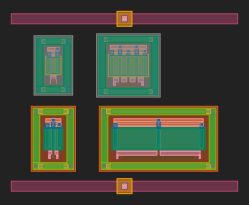

In [5]:
current_mirror.show()
display_component(current_mirror, scale = 1,path=".")

In [6]:
#Adding VIAS
viam1m2 = via_stack(pdk, "met2", "met3", centered=True) #met2 is the bottom layer. met3 is the top layer.
viam2m3 = via_stack(pdk, "met2", "met4", centered=True) #met2 is the bottom layer. met3 is the top layer.

node_A_via = current_mirror << viam1m2
node_A_via_2 = current_mirror << viam1m2

node_A_via.move(m4_ref.ports["gate_S"].center).movex(2.8).movey(-2)
node_A_via_2.move(m4_ref.ports["gate_S"].center).movex(-2.5).movey(-2)

node_B_via = current_mirror << viam1m2
node_B_via.move(m3_ref.ports["gate_S"].center).movex(2.8).movey(-1.5)

via_B_aux = current_mirror << viam1m2
via_B_aux.move(m3_ref.ports["gate_E"].center).movex(2.7)


ComponentReference (parent Component "via_stack_05d99bde", ports ['bottom_layer_W', 'bottom_layer_N', 'bottom_layer_E', 'bottom_layer_S', 'bottom_via_W', 'bottom_via_N', 'bottom_via_E', 'bottom_via_S', 'bottom_met_W', 'bottom_met_N', 'bottom_met_E', 'bottom_met_S', 'top_met_W', 'top_met_N', 'top_met_E', 'top_met_S'], origin (13.934999999999999, 8.790000000000001), rotation 0.0, x_reflection False)

In [7]:
help(via_stack)

Help on function via_stack in module glayout.primitives.via_gen:

via_stack(pdk: glayout.pdk.mappedpdk.MappedPDK, glayer1: str, glayer2: str, centered: bool = True, fullbottom: bool = False, fulltop: bool = False, assume_bottom_via: bool = False, same_layer_behavior: Literal['lay_nothing', 'min_square'] = 'lay_nothing') -> gdsfactory.component.Component
    produces a single via stack between two layers that are routable (metal, poly, or active)
    The via_stack produced is always a square (hieght=width)
    
    args:
    pdk: MappedPDK is the pdk to use
    glayer1: str is the glayer to start on
    glayer2: str is the glayer to end on
    ****NOTE it does not matter what order you pass layers
    fullbottom: if True will lay the bottom layer all over the area of the viastack else makes minimum legal size (ignores min area)
    assume_bottom_via: legalize viastack assuming the via underneath bottom met is present, e.g. if bottom met is met3, assume via2 is present
    fulltop: if Tr

In [8]:
#----------- Adding snippet code to move all the placed components to the proper position, 
#----------- in order to set origin into 0,0
# Place this snippet after all your material polygones are placed, and before your ports are placed
bbox_all = current_mirror.bbox[0]
for ref in current_mirror.references:
    ref.movex(-1*bbox_all[0]).movey(-1*bbox_all[1])

In [9]:
# Añadir nombre de la red (avss) centrado en el riel vertical
current_mirror.add_label(
    text="avss",
    position=(vss_via.center),  # centro del rectángulo
    layer=sky130.get_glayer("met5_label"),
    magnification=1.2
)

# Añadir nombre de la red (avss) centrado en el riel vertical
current_mirror.add_label(
    text="avdd",
    position=(vdd_via.center),  # centro del rectángulo
    layer=sky130.get_glayer("met5_label"),
    magnification=1.2
)

# Add global ports for the supply rails
current_mirror.add_port("avdd", center=vdd_via.center, width=1.0, orientation=180, layer=pdk.get_layer("met4"), port_type="electrical")
current_mirror.add_port("avss", center=vss_via.center, width=1.0, orientation=180, layer=pdk.get_layer("met4"), port_type="electrical")


{'name': 'avss', 'width': 1.0, 'center': [11.35, 0.75], 'orientation': 180, 'layer': [71, 20], 'port_type': 'electrical'}

2026-10-21 23:59:57.427 | WARNING  | gdsfactory.klive:show:48 - Could not connect to klive server. Is klayout open and klive plugin installed?


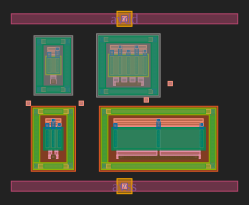

In [10]:
current_mirror.show()
display_component(current_mirror, scale = 1,path=".")

In [11]:
# =========================================================================
# 5. ADD MET2 PHYSICAL PINS AND LABELS FOR LVS
# =========================================================================

# Map port names to their source port objects
pins_to_create = {
    "A": node_A_via.ports["top_met_N"],
    "B": node_B_via.ports["top_met_N"]
}

for pin_name, port in pins_to_create.items():
    # Extract center position, size, and orientation from port object
    center = port.center
    width = port.width
    height = port.width  # Standard square pin area around the port center
    
    current_mirror.add_port(pin_name, center=(center[0], center[1] - height), width=1.0, orientation=180, layer=pdk.get_layer("met3"),  port_type="electrical") 

    # 2. Add text label on met2_pin layer for net identity
    current_mirror.add_label(
        text=pin_name, position=(center[0], center[1] - height), layer=pdk.get_glayer("met3_label"), magnification=1.2
    )
   

2026-10-22 00:00:00.851 | WARNING  | gdsfactory.klive:show:48 - Could not connect to klive server. Is klayout open and klive plugin installed?


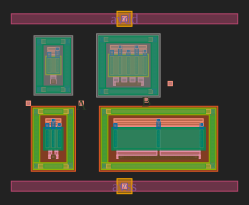

In [12]:
current_mirror.show()
display_component(current_mirror, scale = 1,path=".")

In [13]:
# Connect PMOS bulks to vdd rail
current_mirror << L_route(pdk, m4_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])
current_mirror << L_route(pdk, m3_ref.ports["tie_N_top_met_N"], vdd_via.ports["bottom_met_W"])

# Connect NMOS BULKS TO VSS
current_mirror << L_route(pdk, m1_ref.ports["tie_S_top_met_S"], vss_via.ports["bottom_met_W"])
current_mirror << L_route(pdk, m2_ref.ports["tie_S_top_met_S"], vss_via.ports["bottom_met_W"])

#connecting PMOS SOURCES TO VDD
current_mirror << L_route(pdk,  m4_ref.ports["multiplier_0_source_E"], m4_ref.ports["tie_E_top_met_N"])  # SOURCE m4
current_mirror << L_route(pdk,  m3_ref.ports["multiplier_0_source_E"], m3_ref.ports["tie_E_top_met_N"])  # SOURCE M3

#CONNECTING NMOS SOURCE TO VSS
current_mirror << L_route(pdk,  m1_ref.ports["multiplier_0_source_E"], m1_ref.ports["tie_E_top_met_N"]) #m1
current_mirror << L_route(pdk,  m2_ref.ports["multiplier_0_source_E"], m2_ref.ports["tie_E_top_met_N"]) #m2

ComponentReference (parent Component "L_route_f162a1cf", ports ['array_row0_col0_bottom_layer_W', 'array_row0_col0_bottom_via_W', 'array_row0_col0_bottom_met_W', 'array_row0_col0_top_met_W', 'bottom_lay_W', 'top_met_W', 'array_row0_col0_bottom_layer_N', 'array_row0_col0_bottom_via_N', 'array_row0_col0_bottom_met_N', 'array_row0_col0_top_met_N', 'bottom_lay_N', 'top_met_N', 'array_row0_col0_bottom_layer_E', 'array_row0_col0_bottom_via_E', 'array_row0_col0_bottom_met_E', 'array_row0_col0_top_met_E', 'bottom_lay_E', 'top_met_E', 'array_row0_col0_bottom_layer_S', 'array_row0_col0_bottom_via_S', 'array_row0_col0_bottom_met_S', 'array_row0_col0_top_met_S', 'bottom_lay_S', 'top_met_S'], origin (0.0, 0.0), rotation 0.0, x_reflection False)

In [14]:
current_mirror.show()

2026-10-22 00:00:03.219 | WARNING  | gdsfactory.klive:show:48 - Could not connect to klive server. Is klayout open and klive plugin installed?


In [15]:
#NODE A

current_mirror << L_route(pdk, m4_ref.ports["drain_W"], node_A_via_2.ports["top_met_N"])
current_mirror << L_route(pdk, m1_ref.ports["drain_W"], node_A_via_2.ports["top_met_S"])
current_mirror << L_route(pdk, m4_ref.ports["gate_W"], node_A_via_2.ports["top_met_N"])
current_mirror << L_route(pdk, m1_ref.ports["gate_W"], node_A_via_2.ports["top_met_S"])
current_mirror << straight_route(pdk, node_A_via_2.ports["bottom_met_W"], node_A_via.ports["bottom_met_E"])
current_mirror << L_route(pdk, m2_ref.ports["gate_W"], node_A_via.ports["top_met_S"])


#NODE B
current_mirror << c_route(pdk, m3_ref.ports["drain_E"], node_B_via.ports["bottom_met_E"], extension=2)
current_mirror << straight_route(pdk, m3_ref.ports["gate_E"], via_B_aux.ports["bottom_met_W"])
current_mirror << c_route(pdk, m2_ref.ports["drain_W"], node_B_via.ports["bottom_met_W"], extension=2)


ComponentReference (parent Component "c_route_e30f3b89", ports ['con_N', 'con_S'], origin (0.0, 0.0), rotation 0.0, x_reflection False)

2026-10-22 00:00:05.403 | WARNING  | gdsfactory.klive:show:48 - Could not connect to klive server. Is klayout open and klive plugin installed?


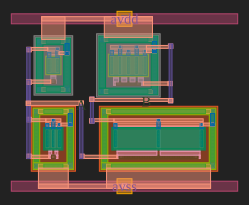

In [16]:
current_mirror.show()
display_component(current_mirror, scale = 1,path=".")

In [17]:
current_mirror.pprint_ports()

┏━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━┓
┃ name ┃ width ┃ center         ┃ orientation ┃ layer    ┃ port_type  ┃
┡━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━━━━┩
│ avdd │ 1.0   │ [11.35, 17.53] │ 180         │ [71, 20] │ electrical │
│ avss │ 1.0   │ [11.35, 0.75]  │ 180         │ [71, 20] │ electrical │
│ A    │ 1.0   │ [7.015, 8.9]   │ 180         │ [70, 20] │ electrical │
│ B    │ 1.0   │ [13.54, 9.23]  │ 180         │ [70, 20] │ electrical │
└──────┴───────┴────────────────┴─────────────┴──────────┴────────────┘

In [18]:
evaluate_bbox(current_mirror)

(22.7, 18.28)

In [19]:
import os
from pathlib import Path
import tempfile

path_to_dir = "/foss/designs/libs/snn_analog/current_mirror/"
magicrc_file = Path(os.environ['PDKPATH']) / "libs.tech" / "magic" / f"{os.environ['PDK']}.magicrc"
design_name=current_mirror.name

pex_path = path_to_dir + "spice/" + f"{current_mirror.name}.spice"
gds_path = path_to_dir + "gds/" + f"{current_mirror.name}.gds"
lef_path = path_to_dir + "lef/" + f"{current_mirror.name}.lef"
current_mirror.write_gds(str(gds_path))


magic_script_content = f"""
drc off            
gds flatglob *\\$\\$*
gds read {gds_path}

flatten {design_name}
load {design_name}
select top cell
extract do local
extract all
ext2sim labels on
ext2sim
extresist tolerance 10
extresist
ext2spice lvs
ext2spice cthresh 0
ext2spice extresist on
ext2spice -o {str(pex_path)}
port avdd use power
port avss use ground
lef write {lef_path}
exit
"""

with tempfile.NamedTemporaryFile(mode='w', delete=False) as magic_script_file:
    magic_script_file.write(magic_script_content)
    magic_script_path = magic_script_file.name
    
magic_cmd = f"bash -c 'magic -rcfile {magicrc_file} -noconsole -dnull < {magic_script_path}'",
magic_subproc = subprocess.run(
    magic_cmd, 
    shell=True,
    check=True,
    capture_output=True
)

magic_subproc_code = magic_subproc.returncode
magic_subproc_out = magic_subproc.stdout.decode('utf-8')
print(magic_subproc_out)




2026-10-22 00:00:09.577 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/foss/designs/libs/snn_analog/current_mirror/gds/current_mirror.gds'



Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Using technology "sky130A", version 1.0.575-2-g7b70722
Library written using GDS-II Release 6.0
Library name: library
Reading "current_mirror".
Reading "L_route_3c1ac51e".
Reading "rectangle_a6a7948e$1".
Reading "L_route_bdc13b53".
Reading "straight_route_ad238839".
Reading "M1".
Reading "L_route_4823708b".
Reading "c_route_e30f3b89".
Reading "compass_a

In [20]:
drc_result = pdk.drc_magic(current_mirror, current_mirror.name)

2026-10-22 00:00:14.151 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/tmp/tmpzel93tsg/current_mirror.gds'


using default pdk_root
Defaulting to stale magic_commands.tcl

Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Loading "/tmp/tmpzel93tsg/magic_commands.tcl" from command line.
Library written using GDS-II Release 6.0
Library name: library
Reading "current_mirror".
Reading "L_route_3c1ac51e".
Reading "rectangle_a6a7948e$1".
Reading "L_route_bdc13b53".
Reading "straight_route_ad238839".
Reading "M1".
Re

In [21]:
import glob
extensions = [
            "els"
            "*.gds",
            "*.ext",
            "*.res.ext",
            "*.lvs.rpt",
            "*_lvs.rpt",
            "*.nodes",
            "*.sim",
            "*.pex.spice",
            "*_pex.spice"
            ]
files_to_delete = []
for ext in extensions:
    files_to_delete.extend(glob.glob(ext))
    
# Delete the files
for file_path in files_to_delete:
    try:
        os.remove(file_path)
        print(f"Deleted: {file_path}")
    except OSError as e:
        print(f"Error deleting {file_path}: {e}")

Deleted: M3.ext
Deleted: L_route_bdc13b53.ext
Deleted: M2.ext
Deleted: straight_route_f7fb7cff.ext
Deleted: L_route_7c3dad77.ext
Deleted: L_route_badd12c6.ext
Deleted: L_route_4823708b.ext
Deleted: rectangle_a6a7948e.ext
Deleted: L_route_94b1eb80.ext
Deleted: compass_a6a7948e.ext
Deleted: via_stack_05d99bde.ext
Deleted: L_route_3c1ac51e.ext
Deleted: L_route_42e0a72e.ext
Deleted: L_route_3df82857.ext
Deleted: M4.ext
Deleted: c_route_da5b6832.ext
Deleted: L_route_26ddd711.ext
Deleted: rectangle_a6a7948e$1.ext
Deleted: L_route_c2a50713.ext
Deleted: c_route_e30f3b89.ext
Deleted: L_route_f162a1cf.ext
Deleted: straight_route_ad238839.ext
Deleted: L_route_d393782b.ext
Deleted: compass_a6a7948e$1.ext
Deleted: M1.ext
Deleted: current_mirror.res.ext
Deleted: via_stack_d964bed5.ext
Deleted: L_route_766d14ac.ext
Deleted: current_mirror.ext
Error deleting current_mirror.res.ext: [Errno 2] No such file or directory: 'current_mirror.res.ext'
Deleted: current_mirror.nodes
Deleted: current_mirror.sim


In [22]:
pdk.lvs_netgen(
    layout=current_mirror,
    design_name = str(current_mirror.name),
    pdk_root = Path(os.environ['PDKPATH']),
    lvs_setup_tcl_file = Path(os.environ['PDKPATH']) / "libs.tech" / "netgen" / f"{os.environ['PDK']}_setup.tcl",
    lvs_schematic_ref_file = Path(str(path_to_dir + "spice/" + "current_mirror.spice")),
    netlist = Path(str(path_to_dir + "sch/" + "current_mirror_sch.spice")),
    output_file_path =  Path(str(path_to_dir))
)


2026-10-22 00:00:16.504 | INFO     | gdsfactory.component:_write_library:1851 - Wrote to '/tmp/tmp6w4vtghm/current_mirror.gds'


using user specified pdk_root, will search for required files in the specified directory

Magic 8.3 revision 636 - Compiled on Thu Apr 16 09:13:57 PM CEST 2026.
Starting magic under Tcl interpreter
Using the terminal as the console.
Using NULL graphics device.
Processing system .magicrc file
Switching to WIRING tool.
Switching to NETLIST tool.
Switching to PICK tool.
Switching to BOX tool.
Sourcing design .magicrc for technology sky130A ...
2 Magic internal units = 1 Lambda
Input style sky130(): scaleFactor=2, multiplier=2
The following types are not handled by extraction and will be treated as non-electrical types:
    ubm 
Scaled tech values by 2 / 1 to match internal grid scaling
Loading sky130A Device Generator Menu ...
Using technology "sky130A", version 1.0.575-2-g7b70722
Library written using GDS-II Release 6.0
Library name: library
Reading "current_mirror".
Reading "L_route_3c1ac51e".
Reading "rectangle_a6a7948e$1".
Reading "L_route_bdc13b53".
Reading "straight_route_ad238839".

{'magic_subproc_code': 0,
 'netgen_subproc_code': 0,
 'result_str': 'LVS run succeeded\nErrors found in LVS report: /tmp/tmp6w4vtghm/current_mirror_lvs.rpt'}